In [24]:
#Importing Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

In [14]:
#Reading Data
df = pd.read_csv('/content/Sample - Superstore.csv',encoding='latin1')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

In [15]:
#Initial Inspection
df.isnull().sum()

,0
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country,0
City,0


In [16]:
#Initial Inspection
df.duplicated().sum()

np.int64(0)

In [17]:
#Cleaning: Column Names & Types

# Standardize column names
df.columns = df.columns.str.strip().str.replace(' ', '_')

# Convert date columns
df['Order_Date'] = pd.to_datetime(df['Order_Date'], format='%m/%d/%Y', errors='coerce')
df['Ship_Date'] = pd.to_datetime(df['Ship_Date'], format='%m/%d/%Y', errors='coerce')

# Drop exact duplicate rows
df = df.drop_duplicates()

# Strip whitespace and fix casing on key text columns
text_cols = ['Segment', 'Region', 'Category', 'Sub-Category', 'Ship_Mode']
for col in text_cols:
    if col in df.columns:
        df[col] = df[col].astype(str).str.strip().str.title()

print("Shape after cleaning:", df.shape)

Shape after cleaning: (9994, 21)


In [18]:
#Cleaning: Logic & Outlier Checks

# Flag rows where Ship Date is before Order Date (data error)
bad_dates = df[df['Ship_Date'] < df['Order_Date']]
print("Rows with Ship Date before Order Date:", len(bad_dates))
df = df[~(df['Ship_Date'] < df['Order_Date'])]

# Check for negative or zero Sales/Quantity
print("Negative/zero Sales rows:", (df['Sales'] <= 0).sum())
print("Negative/zero Quantity rows:", (df['Quantity'] <= 0).sum())

# Discount sanity check (should be between 0 and 1)
print("Discount out of range (0-1):", ((df['Discount'] < 0) | (df['Discount'] > 1)).sum())

# Outlier check on Sales using IQR
Q1, Q3 = df['Sales'].quantile(0.25), df['Sales'].quantile(0.75)
IQR = Q3 - Q1
outliers = df[(df['Sales'] < Q1 - 1.5*IQR) | (df['Sales'] > Q3 + 1.5*IQR)]
print("Sales outliers (IQR method):", len(outliers))

Rows with Ship Date before Order Date: 0
Negative/zero Sales rows: 0
Negative/zero Quantity rows: 0
Discount out of range (0-1): 0
Sales outliers (IQR method): 1167


In [19]:
#Feature Engineering

df['Profit_Margin'] = df['Profit'] / df['Sales']
df['Order_Year'] = df['Order_Date'].dt.year
df['Order_Month'] = df['Order_Date'].dt.to_period('M').astype(str)
df['Shipping_Days'] = (df['Ship_Date'] - df['Order_Date']).dt.days

df.to_csv('Superstore_Cleaned.csv', index=False)
print("Cleaned file saved.")

Cleaned file saved.


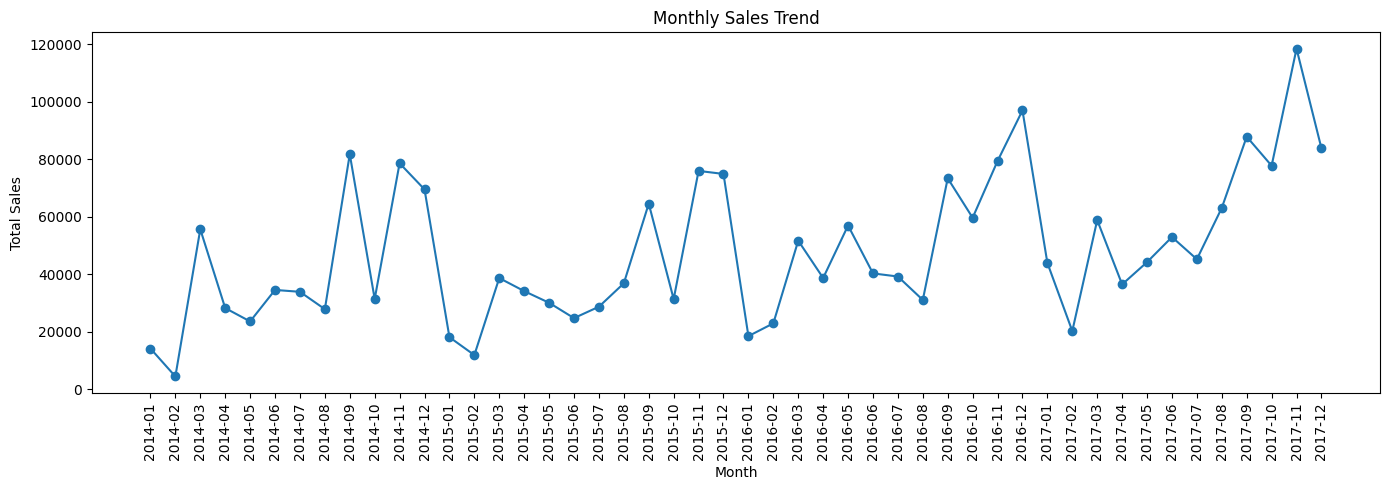

In [20]:
#EDA: Monthly Sales Trend

monthly_sales = df.groupby('Order_Month')['Sales'].sum().reset_index()

plt.figure(figsize=(14, 5))
plt.plot(monthly_sales['Order_Month'], monthly_sales['Sales'], marker='o')
plt.xticks(rotation=90)
plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.tight_layout()
plt.show()

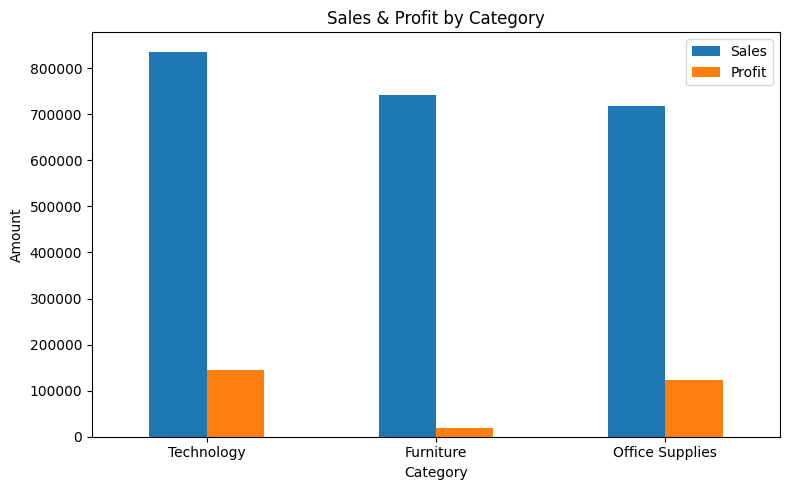

In [21]:
#EDA: Sales & Profit by Category

cat_summary = df.groupby('Category')[['Sales', 'Profit']].sum().sort_values('Sales', ascending=False)

cat_summary.plot(kind='bar', figsize=(8, 5))
plt.title('Sales & Profit by Category')
plt.ylabel('Amount')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

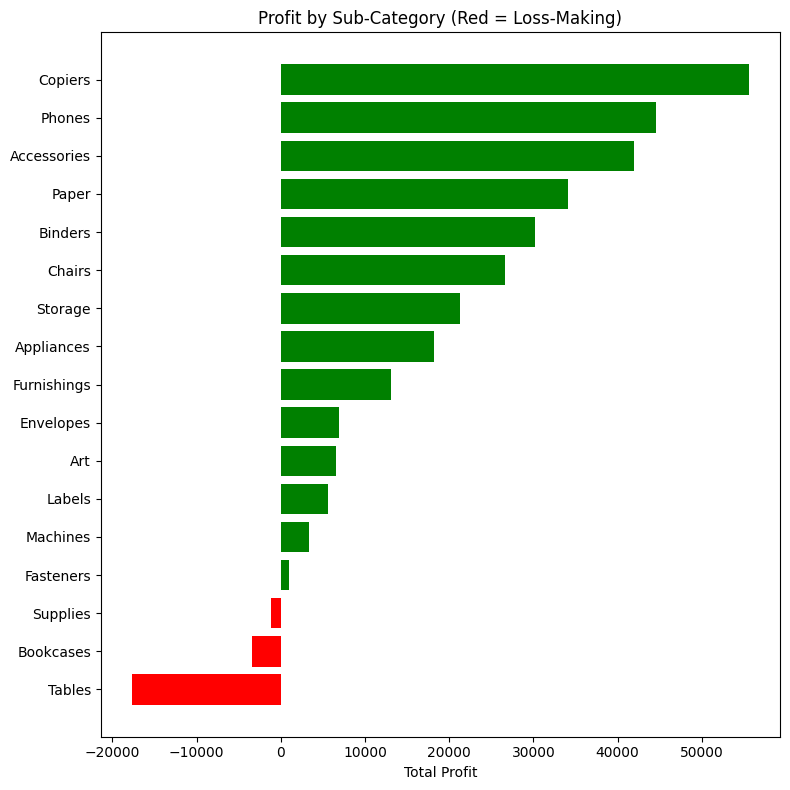

In [22]:
#EDA: Sub-Category Profit (Spot the Losers)

subcat_profit = df.groupby('Sub-Category')['Profit'].sum().sort_values()

plt.figure(figsize=(8, 8))
colors = ['red' if x < 0 else 'green' for x in subcat_profit.values]
plt.barh(subcat_profit.index, subcat_profit.values, color=colors)
plt.title('Profit by Sub-Category (Red = Loss-Making)')
plt.xlabel('Total Profit')
plt.tight_layout()
plt.show()

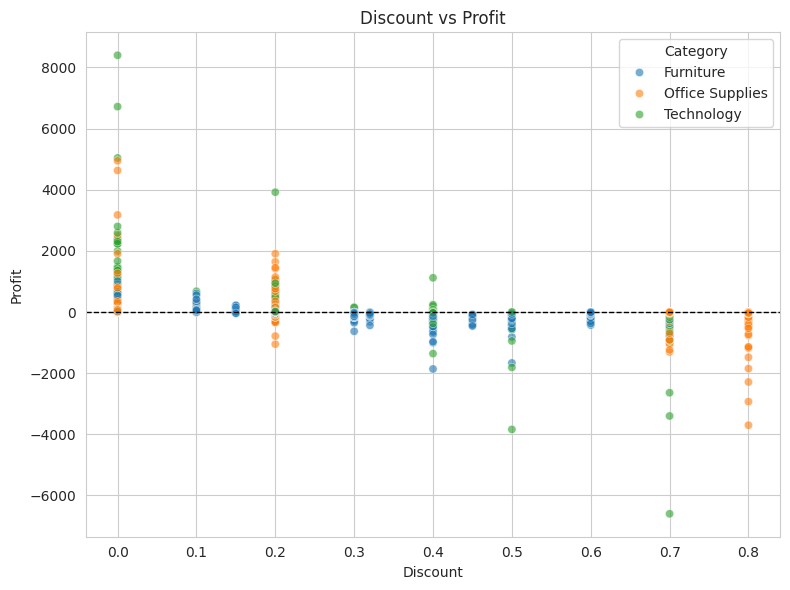

In [25]:
#EDA: Discount vs Profit

plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='Discount', y='Profit', hue='Category', alpha=0.6)
plt.title('Discount vs Profit')
plt.axhline(0, color='black', linestyle='--', linewidth=1)
plt.tight_layout()
plt.show()

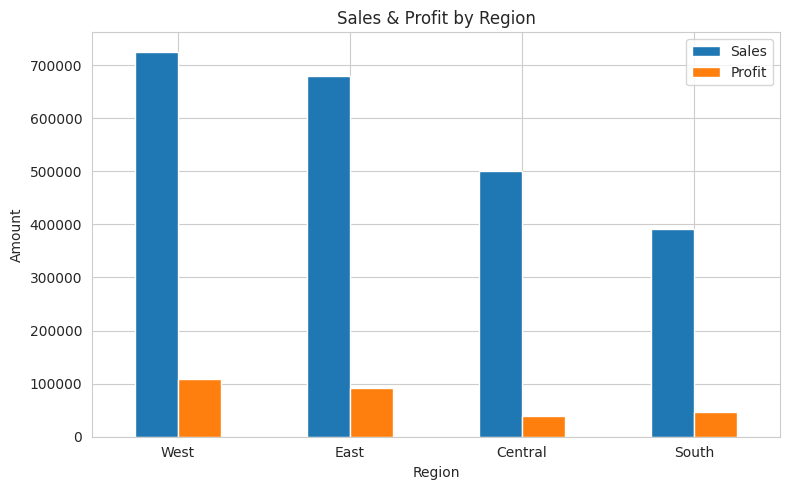

In [26]:
#EDA: Regional Performance

region_summary = df.groupby('Region')[['Sales', 'Profit']].sum().sort_values('Sales', ascending=False)

region_summary.plot(kind='bar', figsize=(8, 5))
plt.title('Sales & Profit by Region')
plt.ylabel('Amount')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

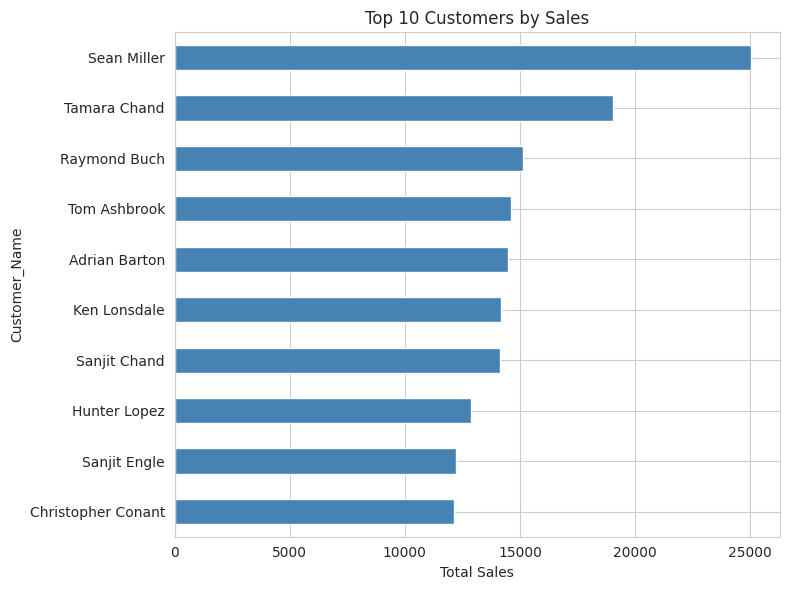

In [27]:
#EDA: Top 10 Customers by Sales

top_customers = df.groupby('Customer_Name')['Sales'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 6))
top_customers.sort_values().plot(kind='barh', color='steelblue')
plt.title('Top 10 Customers by Sales')
plt.xlabel('Total Sales')
plt.tight_layout()
plt.show()

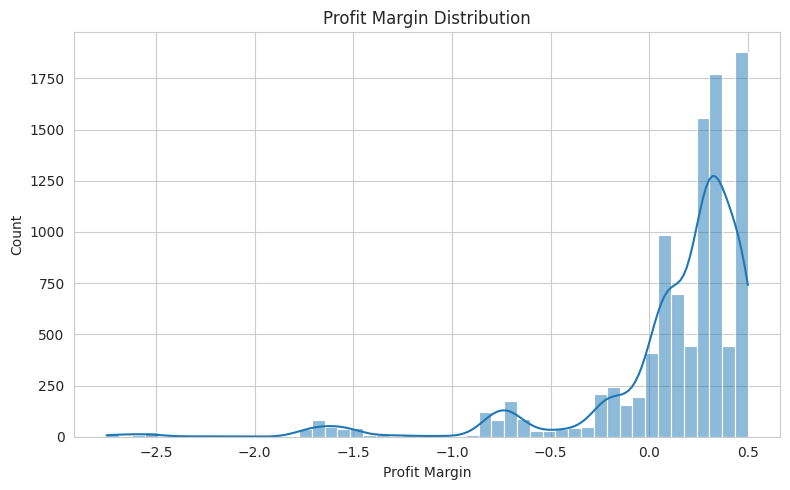

In [28]:
#EDA: Profit Margin Distribution

plt.figure(figsize=(8, 5))
sns.histplot(df['Profit_Margin'], bins=50, kde=True)
plt.title('Profit Margin Distribution')
plt.xlabel('Profit Margin')
plt.tight_layout()
plt.show()